In [37]:
import torch
import numpy as np
import pandas as pd

from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim

import os
import matplotlib.pyplot as plt



In [38]:
class RuscoDataset():

    def __init__(self, data_file):

        all_data = pd.read_csv( data_file, dtype={'xDate':np.float64,
                                                    'yDate':np.float64,
                                                    't2m_now':np.float64,
                                                    't2m_next':np.float64 } )

        self.input_data = (all_data[ ["xDate", "yDate", "t2m_now"] ]).copy()
        self.pred_temps = (all_data[ ["t2m_next"] ]).copy()
    
    def __len__(self):
        return len(self.pred_temps)
    
    def __getitem__(self, indx):

        xDate = self.input_data["xDate"].iloc[indx].item()
        yDate = self.input_data["yDate"].iloc[indx].item()
        now_temp = self.input_data["t2m_now"].iloc[indx].item()
        next_temp = self.pred_temps["t2m_next"].iloc[indx].item()

        dati_input = (xDate, yDate, now_temp)

        return torch.as_tensor(dati_input, dtype=torch.float32), torch.as_tensor(next_temp, dtype=torch.float32)



In [ ]:
train_dataset = RuscoDataset("./poggio_rusco/train_rusco_data.csv")
test_dataset = RuscoDataset("./poggio_rusco/test_rusco_data.csv")

print(len(train_dataset))
print(len(test_dataset))


train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=True)

2921
1095


In [40]:
class StdNet(nn.Module):

    def __init__(self):

        super().__init__()
        self.lay1 = nn.Linear(3, 512)
        self.lay2 = nn.Linear(512, 512)
        self.lay3 = nn.Linear(512, 512)
        self.lay4 = nn.Linear(512, 1)

    def forward(self, x):

        x = torch.sigmoid(self.lay1(x))
        x = torch.sigmoid(self.lay2(x))
        x = torch.sigmoid(self.lay3(x))
        x = self.lay4(x)

        return x[:, 0]



KiNet = StdNet()
#net_parameters = torch.load("./NetParams/KiNetV1.pth",weights_only=True)
#KiNet.load_state_dict(net_parameters)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

KiNet = KiNet.to(device)


cuda:0


In [41]:

input_data, out_temp = next( iter(test_dataloader) )

print(f"dati input: {input_data}")
print(f"temperatura effettiva {out_temp}")
print(f"temperatura calcolata { KiNet(input_data.to(device)) }")

dati input: tensor([[-0.7441, -0.6681, 24.1790]])
temperatura effettiva tensor([23.5842])
temperatura calcolata tensor([0.1289], device='cuda:0', grad_fn=<SelectBackward0>)


In [42]:
criterion = nn.MSELoss(reduction='mean')
optimizer = optim.Adam(KiNet.parameters(),lr=0.001)

for epoch in range(1000):

    epoch_loss = 0

    for j, data in enumerate(train_dataloader, 0):

        input_data, out_temp = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()

        net_output = KiNet(input_data)
        loss = criterion(net_output, out_temp)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()


    print(f"epoch: {epoch}, loss: {epoch_loss}")

epoch: 0, loss: 3420.0403628349304
epoch: 1, loss: 671.1466360092163
epoch: 2, loss: 479.4773151874542
epoch: 3, loss: 421.02625823020935
epoch: 4, loss: 404.32732450962067
epoch: 5, loss: 395.2105873823166
epoch: 6, loss: 385.56914126873016
epoch: 7, loss: 386.0719931125641
epoch: 8, loss: 384.6945607662201
epoch: 9, loss: 398.26367115974426
epoch: 10, loss: 379.998996257782
epoch: 11, loss: 381.90209686756134
epoch: 12, loss: 382.7589247226715
epoch: 13, loss: 384.0464414358139
epoch: 14, loss: 375.9939514398575
epoch: 15, loss: 383.0899283885956
epoch: 16, loss: 383.4627865552902
epoch: 17, loss: 377.6218329668045
epoch: 18, loss: 382.67695128917694
epoch: 19, loss: 379.7384865283966
epoch: 20, loss: 378.6475409269333
epoch: 21, loss: 377.14080286026
epoch: 22, loss: 375.6388430595398
epoch: 23, loss: 372.7934744358063
epoch: 24, loss: 384.4947872161865
epoch: 25, loss: 389.40842604637146
epoch: 26, loss: 380.9525913000107
epoch: 27, loss: 380.14620411396027
epoch: 28, loss: 375.114

In [43]:
def test_net(net, test_loader):

    avg_error = 0

    for j, data in enumerate(test_loader, 0):

        input_data, out_temp = data[0].to(device), data[1].to(device)
        
        net_output = net(input_data)
        avg_error += (torch.abs(net_output - out_temp)) * (1/len(test_loader))

    return avg_error



print(f"test results: {test_net(KiNet, test_dataloader)}")

    

test results: tensor([1.4942], device='cuda:0', grad_fn=<AddBackward0>)


In [44]:

torch.save(KiNet.state_dict(), f'./NetParams/KiNetV1_32.pth')

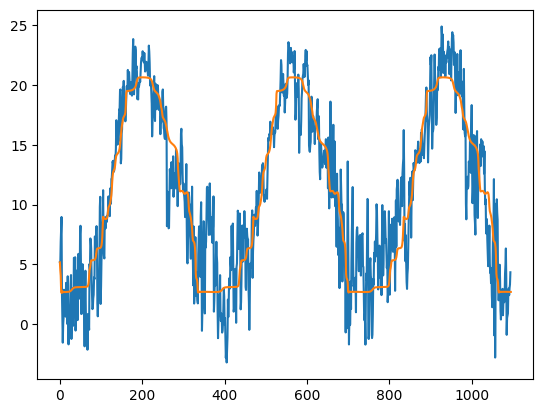

In [45]:

raw_test_data = pd.read_csv( "/home/federico_menegazzo/Desktop/Programming/python_projects/analisi_dati_ki/poggio_rusco/test_rusco_data.csv", dtype = {'day':np.int32,
                                                                           'month':np.int32,
                                                                           'year':np.int32,
                                                                           't2m_now':np.float32,
                                                                           't2m_next':np.float32} )


x0 = 5.159420000000011
iterative_model = [x0]



for indx, entry in raw_test_data.iterrows():

    giorno = entry["xDate"]
    mese = entry["yDate"]

    input_entry = np.array([giorno, mese, x0])

    tensor_input_entry = torch.as_tensor( input_entry, dtype=torch.float32).unsqueeze(0)

    pred_temp = KiNet(tensor_input_entry.to(device))
    iterative_model.append(pred_temp[0].cpu().detach().numpy())

    x0 = pred_temp[0].cpu().detach().numpy()



plt.plot(raw_test_data["t2m_now"].values)
plt.plot(iterative_model)
plt.show()